# 09 - So sánh chuyên sâu các biến thể Quantization 4-bit trên Qwen2.5-0.5B-Instruct

**Mục tiêu:** Đánh giá toàn diện model dưới 1B (`Qwen2.5-0.5B-Instruct`) trên **8 biến thể lượng tử hóa 4-bit**:
1. `Q4_K_M`: Chuẩn K-quant 4-bit phổ biến nhất (baseline đối chứng).
2. `Q4_K_M-imx`: `Q4_K_M` kết hợp ma trận tầm quan trọng (*Importance Matrix*).
3. `IQ4_XS`: Lượng tử hóa phi tuyến (*I-quant*) siêu nhỏ (siêu khối 256 số), dùng bảng tra cứu phi tuyến.
4. `IQ4_NL`: Lượng tử hóa phi tuyến 4-bit (*Non-Linear*, khối 32 số), giữ phân phối trọng số hình chuông chuẩn xác hơn `Q4_0`.
5. `IQ4_XS-imx`: `IQ4_XS` có *Importance Matrix* dẫn đường khi nén.
6. `IQ4_NL-imx`: `IQ4_NL` có *Importance Matrix* dẫn đường khi nén.
7. `Q4_K_M-o4`: `Q4_K_M` nhưng ép riêng lớp đầu ra (`output.weight` / LM Head) xuống `Q4_0` (`--output-tensor-type q4_0`) để giảm dung lượng và tăng tốc sinh token.
8. `Q4_1`: Nén 4-bit cổ điển theo khối 32 số có cả hệ số tỉ lệ (*scale*) và độ lệch (*min/offset*), giải nén nhanh và ít sai số bất đối xứng hơn `Q4_0`.

---

### Vì sao chọn bộ tài liệu hiệu chuẩn lai (Hybrid Calibration Data) cho `-imx`?
Khi chạy `llama-imatrix`, model đọc qua một tập văn bản mẫu để đo mức độ kích hoạt (*activation*) của từng nơ-ron và tính điểm quan trọng $I_j = \sum (x_j)^2$ cho từng cột trọng số:
- Nếu **chỉ dùng `wiki.test.raw`** (văn bản Wikipedia tiếng Anh): Model chỉ biết trọng số nào quan trọng cho văn xuôi thông thường, nhưng **không kích hoạt mạnh các mạch Attention/MLP chuyên xử lý cú pháp JSON, thẻ `<tool_call>` và schema hàm**.
- Nếu **chỉ dùng các câu lệnh gọi tool ngắn**: Ma trận dễ bị quá khớp (*overfit*) vào vài từ khóa hẹp, làm suy giảm khả năng hiểu ngôn ngữ tự nhiên đa dạng của người dùng.
- **Giải pháp tối ưu được áp dụng trong notebook này (`calib_qwen25_imatrix.txt`)**: Kết hợp **văn bản ngôn ngữ tổng quát (`wiki.test.raw`)** + **dữ liệu miền công nghiệp & hội thoại ChatML Native Tool-Calling** (gồm System Prompt chứa JSON Tool Schema của 3/6/11 công cụ, trạng thái telemetry băng tải, câu hỏi trong phạm vi kèm lời giải `<tool_call>{...}</tool_call>`, câu hỏi ngoài phạm vi từ chối gọi hàm, và các bản ghi nhật ký vận hành từ `faith_cases.py`), đồng thời bật cờ `--parse-special --process-output` để đo cả các token đặc biệt (`<|im_start|>`, `<tool_call>`) lẫn tầng từ vựng đầu ra.

In [1]:
import json
import subprocess
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import slm_tools as st
import model_catalog as mc
import tool_cases as T
import faith_cases as F

LLAMA_CPP_DIR = "./llama.cpp"
MODEL_NAME = "Qwen2.5-0.5B-Instruct"
QUANT_DIR = mc.CACHE_DIR / "gguf" / "qwen25_05b_quants"
QUANT_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình chạy llama-bench: đặt BENCH_NGL = 0 để đo tốc độ CPU thuần (phản ánh sát hành vi giải nén trên thiết bị biên),
# hoặc đặt BENCH_NGL = 99 nếu muốn đo trên GPU.
BENCH_THREADS = 4
BENCH_NGL = 0
BENCH_REPS = 3

# 8 biến thể lượng tử hóa cần so sánh
VARIANTS = [
    {"id": "Q4_K_M",     "qtype": "Q4_K_M", "use_imx": False, "extra_args": [],                               "desc": "Chuẩn K-quant 4-bit (đối chứng)"},
    {"id": "Q4_K_M-imx", "qtype": "Q4_K_M", "use_imx": True,  "extra_args": [],                               "desc": "Q4_K_M + Importance Matrix"},
    {"id": "IQ4_XS",     "qtype": "IQ4_XS", "use_imx": False, "extra_args": [],                               "desc": "I-quant 4-bit siêu nhỏ (siêu khối 256)"},
    {"id": "IQ4_NL",     "qtype": "IQ4_NL", "use_imx": False, "extra_args": [],                               "desc": "I-quant 4-bit phi tuyến (khối 32)"},
    {"id": "IQ4_XS-imx", "qtype": "IQ4_XS", "use_imx": True,  "extra_args": [],                               "desc": "IQ4_XS + Importance Matrix"},
    {"id": "IQ4_NL-imx", "qtype": "IQ4_NL", "use_imx": True,  "extra_args": [],                               "desc": "IQ4_NL + Importance Matrix"},
    {"id": "Q4_K_M-o4",  "qtype": "Q4_K_M", "use_imx": False, "extra_args": ["--output-tensor-type", "q4_0"], "desc": "Q4_K_M + ép lớp từ vựng xuống Q4_0"},
    {"id": "Q4_1",       "qtype": "Q4_1",   "use_imx": False, "extra_args": [],                               "desc": "Quant 4-bit khối 32 có scale + min offset"},
]

f16_path = mc.ensure_gguf(MODEL_NAME, "F16", llama_cpp_dir=LLAMA_CPP_DIR)
print(f"File gốc F16: {f16_path} ({mc.gguf_size_mb(f16_path):.1f} MB)")

File gốc F16: model_cache\gguf\Qwen2.5-0.5B-Instruct.F16.gguf (948.1 MB)


## Bước 1 - Xây dựng tài liệu hiệu chuẩn (`calib_qwen25_imatrix.txt`) và tính Importance Matrix

Tệp hiệu chuẩn kết hợp:
1. **Văn bản ngôn ngữ tự nhiên tổng quát (`wiki.test.raw`)**: Giữ độ chính xác ngôn ngữ chung và khả năng đọc hiểu ngữ cảnh đa dạng.
2. **Mẫu hội thoại ChatML & Tool-Calling (`<|im_start|>`, `<tool_call>`)**: Bao gồm định nghĩa JSON Schema của các bộ công cụ (3, 6, 11 tools), dữ liệu trạng thái băng tải, lời gọi hàm chuẩn xác và câu trả lời từ chối khi gặp yêu cầu ngoài phạm vi.
3. **Bản ghi nhật ký kỹ thuật nhà máy (`faith_cases.py`)**: Giúp model bảo toàn các trọng số xử lý số liệu kỹ thuật, mã lỗi và thông số vận hành.

In [2]:
WIKI_PATH = Path("wiki.test.raw")
if not WIKI_PATH.exists():
    from datasets import load_dataset
    WIKI_PATH.write_text(
        "".join(load_dataset("wikitext", "wikitext-2-raw-v1", split="test")["text"]),
        encoding="utf-8",
    )

CALIB_PATH = QUANT_DIR / "calib_qwen25_imatrix.txt"
IMATRIX_PATH = QUANT_DIR / f"{MODEL_NAME}.imatrix.gguf"

def build_hybrid_calibration_file(out_path: Path) -> Path:
    """Tạo tài liệu hiệu chuẩn kết hợp WikiText-2 + ChatML Tool Calling + Industrial Logs."""
    sections = []

    # Phần 1: Văn bản tự nhiên từ WikiText-2 (~120 KB đầu tiên để cân bằng tỉ trọng)
    wiki_text = WIKI_PATH.read_text(encoding="utf-8")[:120_000]
    sections.append(wiki_text)

    # Phần 2: Hội thoại ChatML chứa JSON Tool Schema, câu lệnh gọi hàm <tool_call> và câu trả lời ngoài phạm vi
    cases = T.make_cases()
    tool_sizes = [3, 6, 11]
    chatml_samples = []
    for idx, c in enumerate(cases):
        n_tools = tool_sizes[idx % len(tool_sizes)] if c["core"] else 11
        msgs, tools = T.native_request(c, T.TOOL_SETS[n_tools])
        tools_json = "\n".join(json.dumps(t, ensure_ascii=False) for t in tools)
        sys_prompt = (
            f"{msgs[0]['content']}\n\n"
            "# Tools\n\nYou may call one or more functions to assist with the user query.\n"
            f"You are provided with function signatures within <tools></tools> XML tags:\n<tools>\n{tools_json}\n</tools>\n\n"
            "For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n"
            "<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call>"
        )
        if c["tool"] is not None:
            call_args = dict(c["args"])
            if c["tool"] in ("request_line_restart", "request_line_stop") and "reason" not in call_args:
                call_args["reason"] = "operator requested via voice command"
            assistant_reply = (
                "<tool_call>\n"
                + json.dumps({"name": c["tool"], "arguments": call_args}, ensure_ascii=False)
                + "\n</tool_call>"
            )
        else:
            assistant_reply = (
                "I cannot fulfill that request because it is outside the scope of conveyor line supervision."
            )
        sample = (
            f"<|im_start|>system\n{sys_prompt}<|im_end|>\n"
            f"<|im_start|>user\n{msgs[1]['content']}<|im_end|>\n"
            f"<|im_start|>assistant\n{assistant_reply}<|im_end|>\n"
        )
        chatml_samples.append(sample)

    sections.append("\n".join(chatml_samples))

    # Phần 3: Các đoạn báo cáo kỹ thuật & log nhà máy từ faith_cases.py
    faith_samples = []
    for fc in F.make_cases():
        sys_msg = fc["messages"][0]["content"]
        usr_msg = fc["messages"][1]["content"]
        ans_msg = f"According to the log, the value is {fc['truth']}." if fc["truth"] is not None else "NOT IN LOG"
        faith_samples.append(
            f"<|im_start|>system\n{sys_msg}<|im_end|>\n"
            f"<|im_start|>user\n{usr_msg}<|im_end|>\n"
            f"<|im_start|>assistant\n{ans_msg}<|im_end|>\n"
        )
    sections.append("\n".join(faith_samples))

    full_text = "\n\n".join(sections)
    out_path.write_text(full_text, encoding="utf-8")
    return out_path

build_hybrid_calibration_file(CALIB_PATH)
print(f"Đã tạo file hiệu chuẩn: {CALIB_PATH} ({CALIB_PATH.stat().st_size / 1024:.1f} KB)")

if not IMATRIX_PATH.exists():
    imatrix_bin = mc.find_llama_bin("llama-imatrix", LLAMA_CPP_DIR)
    cmd = [
        str(imatrix_bin),
        "-m", str(f16_path),
        "-f", str(CALIB_PATH),
        "-o", str(IMATRIX_PATH),
        "--process-output",
        "--parse-special",
        "-c", "512",
        "--chunks", "80",
        "-ngl", str(st.GPU_LAYERS),
    ]
    print("Đang tính toán Importance Matrix bằng llama-imatrix...")
    mc._run(cmd)
    print(f"[xong] Đã lưu Importance Matrix tại: {IMATRIX_PATH}")
else:
    print(f"[đã có] Importance Matrix: {IMATRIX_PATH} ({IMATRIX_PATH.stat().st_size / 1024:.1f} KB)")

Đã tạo file hiệu chuẩn: model_cache\gguf\qwen25_05b_quants\calib_qwen25_imatrix.txt (726.9 KB)
Đang tính toán Importance Matrix bằng llama-imatrix...
[run] llama.cpp\build\bin\Release\llama-imatrix.exe -m model_cache\gguf\Qwen2.5-0.5B-Instruct.F16.gguf -f model_cache\gguf\qwen25_05b_quants\calib_qwen25_imatrix.txt -o model_cache\gguf\qwen25_05b_quants\Qwen2.5-0.5B-Instruct.imatrix.gguf --process-output --parse-special -c 512 --chunks 80 -ngl 99
[xong] Đã lưu Importance Matrix tại: model_cache\gguf\qwen25_05b_quants\Qwen2.5-0.5B-Instruct.imatrix.gguf


## Bước 2 - Tạo đủ 8 file GGUF từ bản gốc F16

Sử dụng `llama-quantize` để nén `Qwen2.5-0.5B-Instruct.F16.gguf` sang 8 biến thể.

In [3]:
quant_bin = mc.find_llama_bin("llama-quantize", LLAMA_CPP_DIR)

def get_variant_path(v: dict) -> Path:
    return QUANT_DIR / f"{MODEL_NAME}.{v['id']}.gguf"

quant_rows = []
for v in VARIANTS:
    out_gguf = get_variant_path(v)
    if not out_gguf.exists():
        cmd = [str(quant_bin)]
        if v["use_imx"]:
            cmd += ["--imatrix", str(IMATRIX_PATH)]
        if v["extra_args"]:
            cmd += v["extra_args"]
        cmd += [str(f16_path), str(out_gguf), v["qtype"]]
        print(f"[đang nén] {v['id']} -> {out_gguf.name} ...")
        mc._run(cmd)
    else:
        print(f"[đã có] {out_gguf.name}")

    size_mib = out_gguf.stat().st_size / (1024 ** 2)
    quant_rows.append({
        "Biến thể": v["id"],
        "Kiểu gốc": v["qtype"],
        "Dùng imatrix": "Có" if v["use_imx"] else "Không",
        "Dung lượng (MiB)": round(size_mib, 1),
        "Mô tả": v["desc"],
    })

pd.DataFrame(quant_rows)

[đang nén] Q4_K_M -> Qwen2.5-0.5B-Instruct.Q4_K_M.gguf ...
[run] llama.cpp\build\bin\Release\llama-quantize.exe model_cache\gguf\Qwen2.5-0.5B-Instruct.F16.gguf model_cache\gguf\qwen25_05b_quants\Qwen2.5-0.5B-Instruct.Q4_K_M.gguf Q4_K_M
[đang nén] Q4_K_M-imx -> Qwen2.5-0.5B-Instruct.Q4_K_M-imx.gguf ...
[run] llama.cpp\build\bin\Release\llama-quantize.exe --imatrix model_cache\gguf\qwen25_05b_quants\Qwen2.5-0.5B-Instruct.imatrix.gguf model_cache\gguf\Qwen2.5-0.5B-Instruct.F16.gguf model_cache\gguf\qwen25_05b_quants\Qwen2.5-0.5B-Instruct.Q4_K_M-imx.gguf Q4_K_M
[đang nén] IQ4_XS -> Qwen2.5-0.5B-Instruct.IQ4_XS.gguf ...
[run] llama.cpp\build\bin\Release\llama-quantize.exe model_cache\gguf\Qwen2.5-0.5B-Instruct.F16.gguf model_cache\gguf\qwen25_05b_quants\Qwen2.5-0.5B-Instruct.IQ4_XS.gguf IQ4_XS
[đang nén] IQ4_NL -> Qwen2.5-0.5B-Instruct.IQ4_NL.gguf ...
[run] llama.cpp\build\bin\Release\llama-quantize.exe model_cache\gguf\Qwen2.5-0.5B-Instruct.F16.gguf model_cache\gguf\qwen25_05b_quants\Qwen2

,Biến thể,Kiểu gốc,Dùng imatrix,Dung lượng (MiB),Mô tả
0,Q4_K_M,Q4_K_M,Không,379.4,Chuẩn K-quant 4-bit (đối chứng)
1,Q4_K_M-imx,Q4_K_M,Có,379.4,Q4_K_M + Importance Matrix
2,IQ4_XS,IQ4_XS,Không,335.2,I-quant 4-bit siêu nhỏ (siêu khối 256)
3,IQ4_NL,IQ4_NL,Không,337.9,I-quant 4-bit phi tuyến (khối 32)
4,IQ4_XS-imx,IQ4_XS,Có,333.2,IQ4_XS + Importance Matrix
5,IQ4_NL-imx,IQ4_NL,Có,336.3,IQ4_NL + Importance Matrix
6,Q4_K_M-o4,Q4_K_M,Không,314.5,Q4_K_M + ép lớp từ vựng xuống Q4_0
7,Q4_1,Q4_1,Không,357.2,Quant 4-bit khối 32 có scale + min offset


## Bước 3 - Đo tốc độ (`pp128`, `tg64`) và độ chính xác Tool Calling (156 tình huống)

- **Tốc độ xử lý prompt (`pp128`)** và **tốc độ sinh token (`tg64`)**: Đo trực tiếp bằng `llama-bench -p 128 -n 64`.
- **Độ chính xác Tool Calling**: Chạy toàn bộ 156 ca kiểm thử của `tool_cases.py` (với đủ 11 công cụ) ở chế độ **Native Chat-Template Tool Calling**:
  - `intent_acc`: Tỉ lệ nhận diện đúng ý định (khi nào cần gọi hàm vs khi nào cần từ chối trên toàn bộ 156 ca).
  - `over_calling`: Tỉ lệ gọi hàm thừa ở 24 câu hỏi ngoài phạm vi (*out-of-scope*).
  - `tool_select_acc`: Tỉ lệ chọn đúng tên hàm và đúng tham số trên 132 ca cần gọi công cụ.
  - `overall_acc`: Điểm chính xác tổng hợp trên toàn bộ 156 ca.

In [4]:
bench_bin = mc.find_llama_bin("llama-bench", LLAMA_CPP_DIR)
CASES = T.make_cases()
RESULT_FILE = st.RESULTS_DIR / "qwen25_05b_quants.json"
RAW_DIR = st.RESULTS_DIR / "raw_qwen25_quants"
RAW_DIR.mkdir(parents=True, exist_ok=True)

def measure_speed_llama_bench(gguf_path: Path, threads: int = BENCH_THREADS, ngl: int = BENCH_NGL, reps: int = BENCH_REPS) -> dict:
    """Đo pp128 (prompt token/s) và tg64 (generate token/s) bằng llama-bench."""
    cmd = [
        str(bench_bin),
        "-m", str(gguf_path),
        "-p", "128",
        "-n", "64",
        "-r", str(reps),
        "-t", str(threads),
        "-ngl", str(ngl),
        "-o", "json",
    ]
    proc = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace", check=True)
    stdout = proc.stdout.strip()
    json_start = stdout.find("[")
    data = json.loads(stdout[json_start:])
    pp128_tps, tg64_tps = 0.0, 0.0
    for entry in data:
        if entry.get("n_prompt", 0) > 0 and entry.get("n_gen", 0) == 0:
            pp128_tps = float(entry["avg_ts"])
        elif entry.get("n_gen", 0) > 0 and entry.get("n_prompt", 0) == 0:
            tg64_tps = float(entry["avg_ts"])
    return {"pp128_tps": round(pp128_tps, 2), "tg64_tps": round(tg64_tps, 2)}

def measure_native_tool_calling(cfg: dict) -> dict:
    """Chạy 156 test cases tool-calling (native mode, đủ 11 tools) qua llama-server."""
    rows = []
    tool_names = T.TOOL_SETS[11]
    with st.server(cfg) as srv:
        for c in CASES:
            msgs, tools = T.native_request(c, tool_names)
            out = srv.ask(msgs, tools=tools, max_tokens=150)
            sc = T.score_native(c, out)
            called = bool(out.get("tool_calls"))
            rows.append({
                "id": c["id"],
                "want_tool": c["tool"],
                "want_args": c["args"],
                "noisy": c["noisy"],
                "called": called,
                "tool_calls": out.get("tool_calls", []),
                "text": out.get("text", ""),
                **sc,
            })

    raw_file = RAW_DIR / f"{cfg['quant_id']}.jsonl"
    with raw_file.open("w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

    df = pd.DataFrame(rows)
    in_scope = df[df["want_tool"].notna()]
    oos = df[df["want_tool"].isna()]

    # Intent đúng: cần gọi hàm thì có gọi (called == True), ngoài phạm vi thì không gọi (called == False)
    intent_correct = (
        (in_scope["called"] == True).sum() + (oos["called"] == False).sum()
    ) / len(df)

    return {
        "overall_acc": round(float(df["ok"].mean()), 4),
        "tool_select_acc": round(float(in_scope["ok"].mean()), 4),
        "tool_name_acc": round(float(in_scope["tool_ok"].mean()), 4),
        "intent_acc": round(float(intent_correct), 4),
        "over_calling": round(float(oos["over_trigger"].mean()), 4),
        "clean_acc": round(float(df[~df["noisy"]]["ok"].mean()), 4),
        "noisy_acc": round(float(df[df["noisy"]]["ok"].mean()), 4),
    }

In [5]:
st.RESULTS_DIR.mkdir(exist_ok=True)
saved_results = json.loads(RESULT_FILE.read_text(encoding="utf-8")) if RESULT_FILE.exists() else []
done_map = {r["quant_id"]: r for r in saved_results}

for v in VARIANTS:
    qid = v["id"]
    if qid in done_map:
        print(f"[đã đo] {qid} -> pp128={done_map[qid]['pp128_tps']} t/s, tg64={done_map[qid]['tg64_tps']} t/s, tool_select={done_map[qid]['tool_select_acc']*100:.1f}%")
        continue

    gguf_path = get_variant_path(v)
    size_mib = round(gguf_path.stat().st_size / (1024 ** 2), 1)
    print(f"\n=== Đang đánh giá {MODEL_NAME} ({qid} | {size_mib} MiB) ===")

    t0 = time.perf_counter()
    speed_metrics = measure_speed_llama_bench(gguf_path)
    print(f"  -> Tốc độ: pp128 = {speed_metrics['pp128_tps']:.2f} tok/s | tg64 = {speed_metrics['tg64_tps']:.2f} tok/s")

    cfg = {
        "id": f"{MODEL_NAME}__{qid}",
        "name": MODEL_NAME,
        "quant": "Q4_K_M",
        "quant_id": qid,
        "params_b": 0.5,
        "file": gguf_path,
    }
    tool_metrics = measure_native_tool_calling(cfg)
    elapsed = time.perf_counter() - t0
    print(
        f"  -> Tool Calling: Intent = {tool_metrics['intent_acc']*100:.1f}% | "
        f"Gọi thừa = {tool_metrics['over_calling']*100:.1f}% | "
        f"Chọn đúng tool = {tool_metrics['tool_select_acc']*100:.1f}% | "
        f"Tổng hợp = {tool_metrics['overall_acc']*100:.1f}% ({elapsed:.0f}s)"
    )

    rec = {
        "model": MODEL_NAME,
        "quant_id": qid,
        "qtype": v["qtype"],
        "use_imx": v["use_imx"],
        "size_mib": size_mib,
        **speed_metrics,
        **tool_metrics,
    }
    done_map[qid] = rec
    RESULT_FILE.write_text(
        json.dumps([done_map[x["id"]] for x in VARIANTS if x["id"] in done_map], indent=2, ensure_ascii=False),
        encoding="utf-8",
    )


=== Đang đánh giá Qwen2.5-0.5B-Instruct (Q4_K_M | 379.4 MiB) ===
  -> Tốc độ: pp128 = 328.13 tok/s | tg64 = 75.96 tok/s
  -> Tool Calling: Intent = 57.0% | Gọi thừa = 41.7% | Chọn đúng tool = 42.4% | Tổng hợp = 44.9% (881s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (Q4_K_M-imx | 379.4 MiB) ===
  -> Tốc độ: pp128 = 287.47 tok/s | tg64 = 76.36 tok/s
  -> Tool Calling: Intent = 63.5% | Gọi thừa = 12.5% | Chọn đúng tool = 46.2% | Tổng hợp = 52.6% (560s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (IQ4_XS | 335.2 MiB) ===
  -> Tốc độ: pp128 = 542.80 tok/s | tg64 = 144.68 tok/s
  -> Tool Calling: Intent = 64.1% | Gọi thừa = 0.0% | Chọn đúng tool = 33.3% | Tổng hợp = 43.6% (411s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (IQ4_NL | 337.9 MiB) ===
  -> Tốc độ: pp128 = 555.71 tok/s | tg64 = 146.55 tok/s
  -> Tool Calling: Intent = 64.7% | Gọi thừa = 0.0% | Chọn đúng tool = 34.1% | Tổng hợp = 44.2% (495s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (IQ4_XS-imx | 333.2 MiB) ===
  -> Tốc độ: pp128 = 432.9

## Bước 4 - Bảng tổng hợp kết quả và Biểu đồ so sánh

In [6]:
records = json.loads(RESULT_FILE.read_text(encoding="utf-8"))
df_res = pd.DataFrame(records)

# Tính phần trăm thay đổi tốc độ so với bản đối chứng Q4_K_M
base_row = df_res[df_res["quant_id"] == "Q4_K_M"].iloc[0]
base_pp = base_row["pp128_tps"]
base_tg = base_row["tg64_tps"]

table_rows = []
for _, r in df_res.iterrows():
    d_pp = (r["pp128_tps"] - base_pp) / base_pp * 100 if base_pp else 0.0
    d_tg = (r["tg64_tps"] - base_tg) / base_tg * 100 if base_tg else 0.0
    pp_str = f"{r['pp128_tps']:.2f}" if r["quant_id"] == "Q4_K_M" else f"{r['pp128_tps']:.2f} ({d_pp:+.0f}%)"
    tg_str = f"{r['tg64_tps']:.2f}" if r["quant_id"] == "Q4_K_M" else f"{r['tg64_tps']:.2f} ({d_tg:+.0f}%)"
    table_rows.append({
        "Bản Quant": r["quant_id"],
        "File (MiB)": f"{r['size_mib']:.0f} MiB",
        "Nhận token (pp128)": pp_str,
        "Sinh token (tg64)": tg_str,
        "Intent": f"{r['intent_acc']*100:.1f}%",
        "Gọi thừa": f"{r['over_calling']*100:.1f}%",
        "Chọn đúng tool": f"{r['tool_select_acc']*100:.1f}%",
        "Điểm tổng (156 ca)": f"{r['overall_acc']*100:.1f}%",
    })

df_display = pd.DataFrame(table_rows)
df_display

,Bản Quant,File (MiB),Nhận token (pp128),Sinh token (tg64),Intent,Gọi thừa,Chọn đúng tool,Điểm tổng (156 ca)
0,Q4_K_M,379 MiB,328.13,75.96,57.0%,41.7%,42.4%,44.9%
1,Q4_K_M-imx,379 MiB,287.47 (-12%),76.36 (+1%),63.5%,12.5%,46.2%,52.6%
2,IQ4_XS,335 MiB,542.80 (+65%),144.68 (+90%),64.1%,0.0%,33.3%,43.6%
3,IQ4_NL,338 MiB,555.71 (+69%),146.55 (+93%),64.7%,0.0%,34.1%,44.2%
4,IQ4_XS-imx,333 MiB,432.96 (+32%),111.35 (+47%),54.5%,0.0%,34.8%,44.9%
5,IQ4_NL-imx,336 MiB,546.91 (+67%),153.04 (+101%),55.1%,0.0%,35.6%,45.5%
6,Q4_K_M-o4,314 MiB,496.45 (+51%),124.10 (+63%),56.4%,29.2%,34.1%,39.7%
7,Q4_1,357 MiB,296.05 (-10%),127.40 (+68%),15.4%,0.0%,0.0%,15.4%


Đã lưu biểu đồ tại: charts\09_qwen25_05b_quant_comparison.png


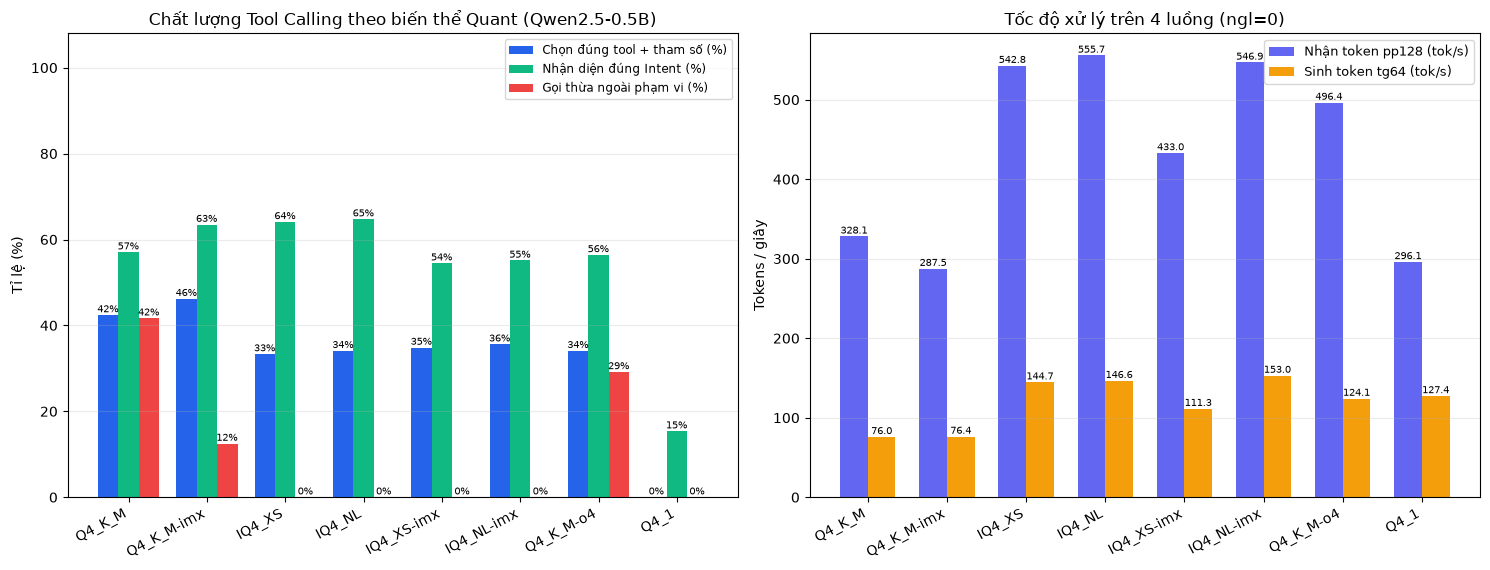

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

x = np.arange(len(df_res))
labels = df_res["quant_id"].tolist()

# Biểu đồ 1: Chất lượng Tool Calling (%)
w = 0.26
ax1 = axes[0]
b1 = ax1.bar(x - w, df_res["tool_select_acc"] * 100, w, label="Chọn đúng tool + tham số (%)", color="#2563eb")
b2 = ax1.bar(x,     df_res["intent_acc"] * 100,      w, label="Nhận diện đúng Intent (%)",    color="#10b981")
b3 = ax1.bar(x + w, df_res["over_calling"] * 100,    w, label="Gọi thừa ngoài phạm vi (%)",   color="#ef4444")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=28, ha="right")
ax1.set_ylim(0, 108)
ax1.set_ylabel("Tỉ lệ (%)")
ax1.set_title("Chất lượng Tool Calling theo biến thể Quant (Qwen2.5-0.5B)")
ax1.legend(loc="upper right", fontsize=8.5)
ax1.grid(axis="y", alpha=0.25)

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.0f}%", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7.5)

# Biểu đồ 2: Tốc độ pp128 và tg64 (tokens/s)
ax2 = axes[1]
w2 = 0.35
s1 = ax2.bar(x - w2/2, df_res["pp128_tps"], w2, label="Nhận token pp128 (tok/s)", color="#6366f1")
s2 = ax2.bar(x + w2/2, df_res["tg64_tps"],  w2, label="Sinh token tg64 (tok/s)",  color="#f59e0b")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=28, ha="right")
ax2.set_ylabel("Tokens / giây")
ax2.set_title(f"Tốc độ xử lý trên {BENCH_THREADS} luồng (ngl={BENCH_NGL})")
ax2.legend(loc="upper right", fontsize=9)
ax2.grid(axis="y", alpha=0.25)

for bars in (s1, s2):
    for bar in bars:
        h = bar.get_height()
        ax2.annotate(f"{h:.1f}", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7.5)

fig.tight_layout()
st.CHARTS_DIR.mkdir(exist_ok=True)
chart_path = st.CHARTS_DIR / "09_qwen25_05b_quant_comparison.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
print(f"Đã lưu biểu đồ tại: {chart_path}")
plt.show()